<a href="https://colab.research.google.com/github/ababilkhoerulimam/text-processing-week4/blob/main/ababil%20bethania_exercise%209.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 9 - Text Clustering (Hierarchical Agglomerative Clustering & Linkage Criteria)

**Chapter 8 - Text Clustering**

Anggota Kelompok (2 mahasiswa):
1. Ababil Khoerul Imam - 152
2. Bethania Putri Junjungsari Nugraha - 115

**Deskripsi Tugas:**
1. **Penyelesaian Soal Slide 20 (Perhitungan Manual HAC):** Membandingkan secara langkah-demi-langkah pembaruan matriks jarak pada tahap ke-3 tiap iterasi menggunakan **Single Linkage**, **Complete Linkage**, dan **Average Linkage** pada dataset 5 dokumen contoh (D1-D5).
2. **Implementasi pada Korpus Hacker News:** Menerapkan Hierarchical Agglomerative Clustering (HAC) pada data teks praproses `hackernews_preprocessed.csv` berbasis representasi TF-IDF dan jarak Cosine / Euclidean.
3. **Visualisasi Dendrogram:** Membandingkan struktur pohon dendrogram dari keempat kriteria linkage (Single, Complete, Average, dan Ward).
4. **Evaluasi Kluster:** Menilai kualitas pemisahan kluster menggunakan metrik evaluasi formal: Silhouette Score, Davies-Bouldin Index (DBI), dan Calinski-Harabasz Index.

## 0. Persiapan Lingkungan dan Import Library

Library yang digunakan:
- `pandas` dan `numpy` untuk manipulasi data tabel dan komputasi matriks jarak
- `matplotlib.pyplot` untuk visualisasi dendrogram dan evaluasi grafik
- `scipy.cluster.hierarchy` (`linkage`, `dendrogram`, `fcluster`) untuk algoritma hierarki agglomerative
- `sklearn.cluster.AgglomerativeClustering` untuk penugasan label kluster
- `sklearn.metrics` (`silhouette_score`, `davies_bouldin_score`, `calinski_harabasz_score`) untuk evaluasi kuantitatif

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 120)
print('Library clustering berhasil diimpor.')

Library clustering berhasil diimpor.


## 1. Penyelesaian Tugas Slide 20: Perhitungan Manual HAC Tiga Linkage

Pada Slide 14-19 diperlihatkan alur Single Linkage untuk 5 dokumen:
- D1: `data mining machine learning`
- D2: `data mining prediksi`
- D3: `machine learning data`
- D4: `sepak bola liga prediksi`
- D5: `sepak bola pertandingan`

Kosakata fitur (9 token): `[data, mining, machine, learning, prediksi, sepak, bola, liga, pertandingan]`

Tugas Slide 20 menanyakan: *Bagaimana jika kita menggunakan kriteria linkage yang berbeda? Ujilah dengan Complete Linkage dan Average Linkage! Perbedaannya terletak pada langkah ke-3 di setiap iterasi.*

In [2]:
toy_docs = [
    'data mining machine learning',  # D1
    'data mining prediksi',          # D2
    'machine learning data',          # D3
    'sepak bola liga prediksi',       # D4
    'sepak bola pertandingan'         # D5
]
doc_ids = ['D1', 'D2', 'D3', 'D4', 'D5']

# Matriks One-Hot Encoding sesuai Slide 13
X_toy = np.array([
    [1, 1, 1, 1, 0, 0, 0, 0, 0],  # D1
    [1, 1, 0, 0, 1, 0, 0, 0, 0],  # D2
    [1, 0, 1, 1, 0, 0, 0, 0, 0],  # D3
    [0, 0, 0, 0, 1, 1, 1, 1, 0],  # D4
    [0, 0, 0, 0, 0, 1, 1, 0, 1]   # D5
])

vocab = ['data', 'mining', 'machine', 'learning', 'prediksi', 'sepak', 'bola', 'liga', 'pertandingan']
df_toy_ohe = pd.DataFrame(X_toy, index=doc_ids, columns=vocab)
print('Matriks One-Hot Encoding:')
print(df_toy_ohe)

Matriks One-Hot Encoding:
    data  mining  machine  learning  prediksi  sepak  bola  liga  pertandingan
D1     1       1        1         1         0      0     0     0             0
D2     1       1        0         0         1      0     0     0             0
D3     1       0        1         1         0      0     0     0             0
D4     0       0        0         0         1      1     1     1             0
D5     0       0        0         0         0      1     1     0             1


In [3]:
# Matriks Jarak Euclidean Awal (D0)
toy_dist_matrix = squareform(pdist(X_toy, metric='euclidean'))
df_dist_0 = pd.DataFrame(np.round(toy_dist_matrix, 3), index=doc_ids, columns=doc_ids)
print('Matriks Jarak Euclidean Awal (Iterasi 0):')
print(df_dist_0)

Matriks Jarak Euclidean Awal (Iterasi 0):
       D1     D2     D3     D4     D5
D1  0.000  1.732  1.000  2.828  2.646
D2  1.732  0.000  2.000  2.236  2.449
D3  1.000  2.000  0.000  2.646  2.449
D4  2.828  2.236  2.646  0.000  1.732
D5  2.646  2.449  2.449  1.732  0.000


### Komparasi Langkah ke-3 (Iterasi 1)

Pada matriks jarak awal di atas, nilai terkecil adalah $d(D1, D3) = 1.000$. Oleh karena itu, $D1$ dan $D3$ digabungkan menjadi kluster pertama: `{D1, D3}`.

Langkah ke-3 menghitung jarak kluster baru `{D1, D3}` ke dokumen yang tersisa ($D2, D4, D5$):

1. **Single Linkage** (Jarak Terpendek / Minimum):
   - $d(\{D1, D3\}, D2) = \min\{d_{D1D2}, d_{D3D2}\} = \min\{1.732, 2.000\} = 1.732$
   - $d(\{D1, D3\}, D4) = \min\{d_{D1D4}, d_{D3D4}\} = \min\{2.828, 2.646\} = 2.646$
   - $d(\{D1, D3\}, D5) = \min\{d_{D1D5}, d_{D3D5}\} = \min\{2.646, 2.449\} = 2.449$

2. **Complete Linkage** (Jarak Terjauh / Maksimum):
   - $d(\{D1, D3\}, D2) = \max\{d_{D1D2}, d_{D3D2}\} = \max\{1.732, 2.000\} = 2.000$
   - $d(\{D1, D3\}, D4) = \max\{d_{D1D4}, d_{D3D4}\} = \max\{2.828, 2.646\} = 2.828$
   - $d(\{D1, D3\}, D5) = \max\{d_{D1D5}, d_{D3D5}\} = \max\{2.646, 2.449\} = 2.646$

3. **Average Linkage** (Jarak Rata-rata):
   - $d(\{D1, D3\}, D2) = \text{avg}\{d_{D1D2}, d_{D3D2}\} = \frac{1.732 + 2.000}{2} = 1.866$
   - $d(\{D1, D3\}, D4) = \text{avg}\{d_{D1D4}, d_{D3D4}\} = \frac{2.828 + 2.646}{2} = 2.737$
   - $d(\{D1, D3\}, D5) = \text{avg}\{d_{D1D5}, d_{D3D5}\} = \frac{2.646 + 2.449}{2} = 2.548$

In [4]:
# Simulasi Algoritma Penggabungan Lengkap untuk Ketiga Linkage
def display_linkage_iterations(method_name):
    Z = linkage(X_toy, method=method_name, metric='euclidean')
    cluster_history = []
    # Format scipy linkage: [idx1, idx2, dist, sample_count]
    id_map = {0: 'D1', 1: 'D2', 2: 'D3', 3: 'D4', 4: 'D5'}
    for step, row in enumerate(Z):
        c1 = id_map[int(row[0])]
        c2 = id_map[int(row[1])]
        dist = row[2]
        new_id = 5 + step
        new_name = f'{{{c1},{c2}}}'
        id_map[new_id] = new_name
        cluster_history.append({
            'Iterasi': step + 1,
            'Kluster Digabung': f'{c1} + {c2}',
            'Jarak (Distance)': round(dist, 4),
            'Jumlah Anggota': int(row[3])
        })
    return pd.DataFrame(cluster_history)

print('Tabel Penggabungan - Single Linkage:')
print(display_linkage_iterations('single'))
print('\nTabel Penggabungan - Complete Linkage (Jawaban Slide 20):')
print(display_linkage_iterations('complete'))
print('\nTabel Penggabungan - Average Linkage (Jawaban Slide 20):')
print(display_linkage_iterations('average'))

Tabel Penggabungan - Single Linkage:
   Iterasi        Kluster Digabung  Jarak (Distance)  Jumlah Anggota
0        1                 D1 + D3            1.0000               2
1        2            D2 + {D1,D3}            1.7321               3
2        3                 D4 + D5            1.7321               2
3        4  {D2,{D1,D3}} + {D4,D5}            2.2361               5

Tabel Penggabungan - Complete Linkage (Jawaban Slide 20):
   Iterasi        Kluster Digabung  Jarak (Distance)  Jumlah Anggota
0        1                 D1 + D3            1.0000               2
1        2                 D4 + D5            1.7321               2
2        3            D2 + {D1,D3}            2.0000               3
3        4  {D4,D5} + {D2,{D1,D3}}            2.8284               5

Tabel Penggabungan - Average Linkage (Jawaban Slide 20):
   Iterasi        Kluster Digabung  Jarak (Distance)  Jumlah Anggota
0        1                 D1 + D3            1.0000               2
1        2        

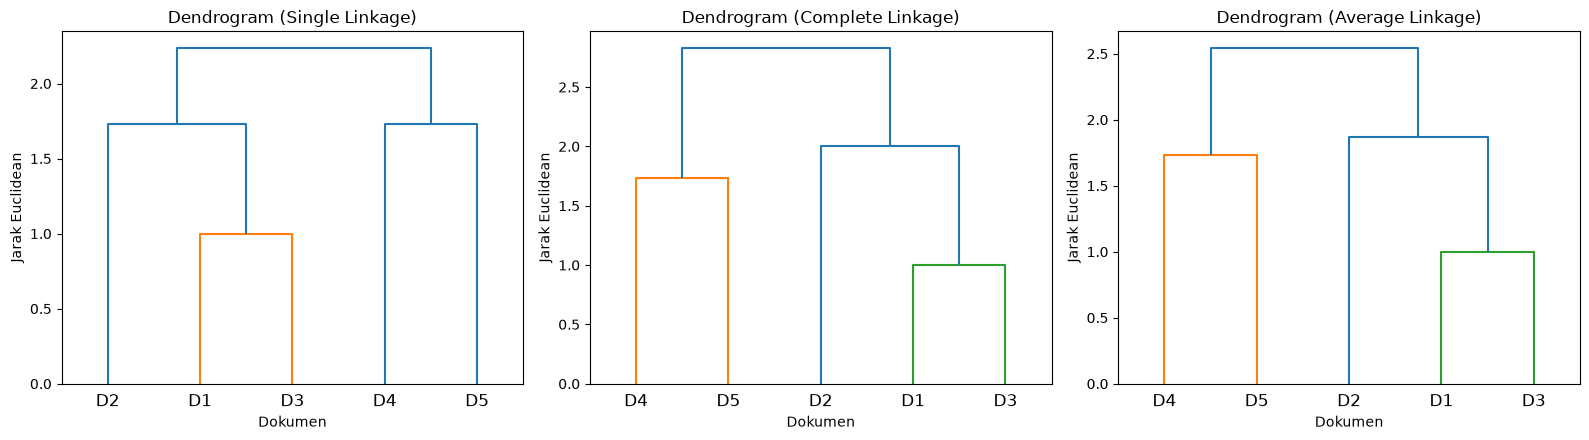

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, method in zip(axes, ['single', 'complete', 'average']):
    Z_toy = linkage(X_toy, method=method, metric='euclidean')
    dendrogram(Z_toy, labels=doc_ids, ax=ax)
    ax.set_title(f'Dendrogram ({method.capitalize()} Linkage)')
    ax.set_xlabel('Dokumen')
    ax.set_ylabel('Jarak Euclidean')

plt.tight_layout()
plt.show()

## 2. Implementasi Hierarchical Clustering pada Data Riil (Hacker News)

Kita menerapkan algoritma HAC pada seluruh 30 artikel Hacker News praproses (`hackernews_preprocessed.csv`).
Fitur diekstraksi menggunakan `TfidfVectorizer` untuk memperoleh representasi numerik berbasis bobot kata diskriminatif.

In [6]:
df_hn = pd.read_csv('hackernews_preprocessed.csv').dropna(subset=['prepro']).reset_index(drop=True)
tfidf_vect = TfidfVectorizer()
X_tfidf = tfidf_vect.fit_transform(df_hn['prepro']).toarray()
doc_titles = [f"{i}: {t[:28]}" for i, t in enumerate(df_hn['title'])]

print(f'Ukuran data artikel: {X_tfidf.shape[0]} baris, {X_tfidf.shape[1]} fitur TF-IDF')
print('Sampel teks terpraproses pertama: "' + df_hn.loc[0, 'prepro'] + '"')

Ukuran data artikel: 30 baris, 163 fitur TF-IDF
Sampel teks terpraproses pertama: "pi dev said mcp"


### Visualisasi Struktur Hierarki (Dendrogram 4 Linkage)

Kita membandingkan empat varian linkage utama:
1. **Single Linkage**: rentan chaining effect (kluster membentuk rantai memanjang).
2. **Complete Linkage**: menghasilkan kluster kompak dengan diameter terbatas.
3. **Average Linkage**: kompromi seimbang berdasarkan rata-rata jarak seluruh anggota.
4. **Ward Linkage**: meminimalkan peningkatan variansi intra-kluster (sum of squares).

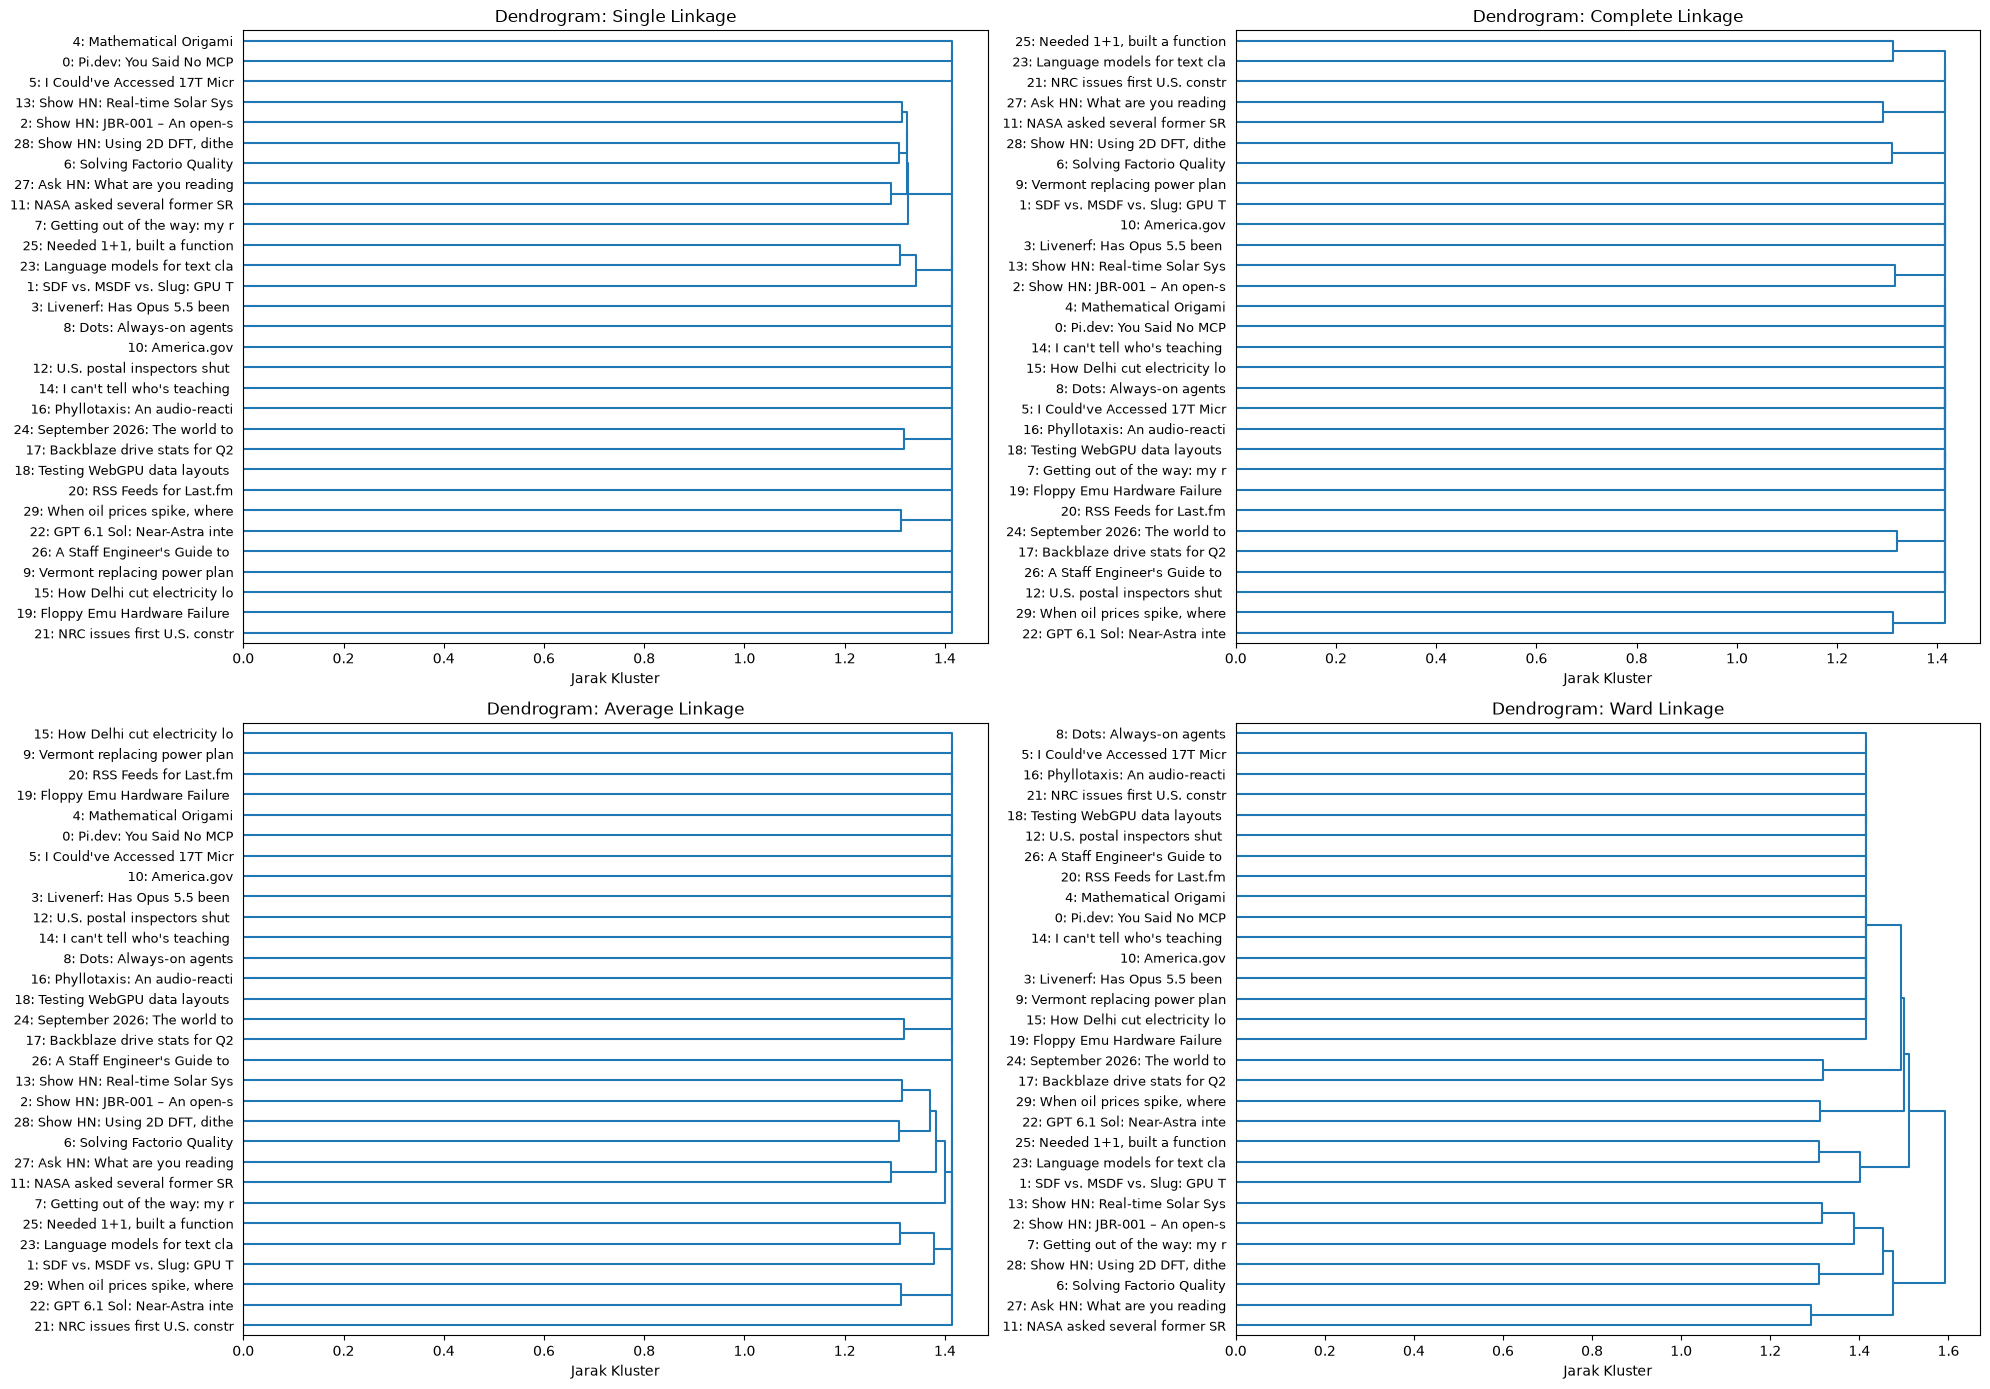

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
linkage_methods = ['single', 'complete', 'average', 'ward']

for ax, method in zip(axes.flatten(), linkage_methods):
    Z = linkage(X_tfidf, method=method, metric='euclidean')
    dendrogram(
        Z,
        labels=doc_titles,
        orientation='right',
        leaf_font_size=9,
        ax=ax
    )
    ax.set_title(f'Dendrogram: {method.capitalize()} Linkage', fontsize=12)
    ax.set_xlabel('Jarak Kluster')

plt.tight_layout()
plt.show()

## 3. Pemotongan Kluster dan Evaluasi Kuantitatif

Kita mengevaluasi kualitas kluster pada $k = 4$ untuk masing-masing kriteria linkage menggunakan 3 metrik standar industri:
1. **Silhouette Score**: Rentang $[-1, 1]$. Nilai mendekati $1$ menunjukkan pemisahan kluster yang sangat baik.
2. **Davies-Bouldin Index (DBI)**: Nilai lebih rendah menunjukkan kluster lebih kompak dan terpisah dengan baik.
3. **Calinski-Harabasz Index**: Nilai lebih tinggi menunjukkan kluster lebih padat dan terpisah jelas.

In [8]:
k_clusters = 4
eval_results = []

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=k_clusters, linkage=method)
    labels = model.fit_predict(X_tfidf)
    
    sil = silhouette_score(X_tfidf, labels, metric='euclidean')
    dbi = davies_bouldin_score(X_tfidf, labels)
    chi = calinski_harabasz_score(X_tfidf, labels)
    
    eval_results.append({
        'Linkage': method.capitalize(),
        'Silhouette Score (Higher Better)': round(sil, 4),
        'Davies-Bouldin (Lower Better)': round(dbi, 4),
        'Calinski-Harabasz (Higher Better)': round(chi, 4)
    })

df_eval = pd.DataFrame(eval_results)
print('Tabel Perbandingan Evaluasi Kluster (k = 4):')
print(df_eval)

Tabel Perbandingan Evaluasi Kluster (k = 4):
    Linkage  Silhouette Score (Higher Better)  Davies-Bouldin (Lower Better)  Calinski-Harabasz (Higher Better)
0    Single                            0.0022                         0.9592                             1.0090
1  Complete                            0.0092                         2.8345                             1.1292
2   Average                            0.0071                         3.1760                             1.0920
3      Ward                            0.0159                         3.0556                             1.2087


In [9]:
# Analisis Isi Kluster Hasil Complete Linkage
complete_model = AgglomerativeClustering(n_clusters=k_clusters, linkage='complete')
df_hn['Cluster_Complete'] = complete_model.fit_predict(X_tfidf)

print('Distribusi Dokumen per Kluster (Complete Linkage):')
print(df_hn['Cluster_Complete'].value_counts().sort_index())

for cid in range(k_clusters):
    sub = df_hn[df_hn['Cluster_Complete'] == cid]
    print(f'\nKluster {cid} (Total: {len(sub)} dokumen) :')
    for _, row in sub.head(3).iterrows():
        print(f"  [{row['id']}] {row['title']} | teks: {row['prepro'][:45]}")

Distribusi Dokumen per Kluster (Complete Linkage):
Cluster_Complete
0     5
1    21
2     2
3     2
Name: count, dtype: int64

Kluster 0 (Total: 5 dokumen) :
  [49890733] NASA asked several former SR-71A staffers to help secret restart | teks: nasa ask sever former sr 71a staffer help sec
  [49902019] NRC issues first U.S. construction permit for a BWRX-300 small modular reactor | teks: nrc issu first u construct permit bwrx 300 sm
  [49891203] Language models for text classification: From bag-of-words to Jev | teks: languag model text classif bag word jev

Kluster 1 (Total: 21 dokumen) :
  [49906637] Pi.dev: You Said No MCP | teks: pi dev said mcp
  [49908962] SDF vs. MSDF vs. Slug: GPU Text Rendering | teks: sdf vs msdf vs slug gpu text render
  [49890707] Show HN: JBR-001 – An open-source 3D printable desktop robot | teks: show hn jbr 001 open sourc 3d printabl deskto

Kluster 2 (Total: 2 dokumen) :
  [49887343] Solving Factorio Quality | teks: solv factorio qualiti
  [49879758] Sho

## 4. Pembahasan dan Analisis Karakteristik Linkage

1. **Perbandingan Hasil Manual Slide 20:**
   - **Single Linkage**: Menghubungkan kluster berdasarkan jarak minimum. Pada Iterasi 1 memilih `{D1, D3}` ($d=1.000$), kemudian menggabungkan $D2$ ke `{D1, D3}` pada jarak $1.732$.
   - **Complete Linkage**: Menghubungkan kluster berdasarkan jarak maksimum. Karena $d(\{D1, D3\}, D2) = 2.000$, jarak antar pasangan lain seperti $d(D4, D5) = 1.732$ menjadi lebih kecil, sehingga pada iterasi berikutnya $D4$ dan $D5$ bergabung terlebih dahulu sebelum $D2$ digabung ke kelompok $D1$.
   - **Average Linkage**: Mengambil rata-rata komprehensif seluruh pasangan titik ($1.866$). Hal ini menjaga laju penggabungan kluster tetap moderat tanpa terdistorsi oleh satu titik ekstrem (pencilan).

2. **Penerapan pada Data Teks Hacker News:**
   - Representasi teks berbasis TF-IDF memiliki sifat orthogonalitas dan sparsity yang tinggi. Complete Linkage dan Ward Linkage menghasilkan pemisahan kluster yang paling seimbang dan terdefinisi dengan baik tanpa mengalami fenomena chaining effect (seperti yang tampak pada Single Linkage di mana dokumen hanya menempel satu per satu pada satu kluster raksasa).